## 5. Granger causality screening

[![content: AI-generated](../_static/badges/ai-generated.svg)](ai-acknowledgement) [![content: human-reviewed & edited](../_static/badges/human-reviewed-edited.svg)](ai-acknowledgement)

Granger tests are retained as predictive screens only. A significant result means past values of a predictor contain incremental predictive information for CPI inflation conditional on past CPI inflation. Granger causality is not structural or economic causality, especially for policy variables such as the RBA cash rate that also respond to inflation.

Each test regresses the target's quarterly change on its own recent lags plus lags of one predictor, with both lag counts (1 to 4) chosen by BIC on a common sample, then runs an F-test of whether the predictor's lags add anything. Two choices are deliberate. The target is quarterly CPI, not the YoY series the models forecast, because overlapping YoY windows leave autocorrelated residuals and make the p-values far too small. And the lag comes from BIC, not from the tallest bar in [§4](04_lead_lag_correlation), so we aren't testing a lag that was picked because it looked good on the same data.

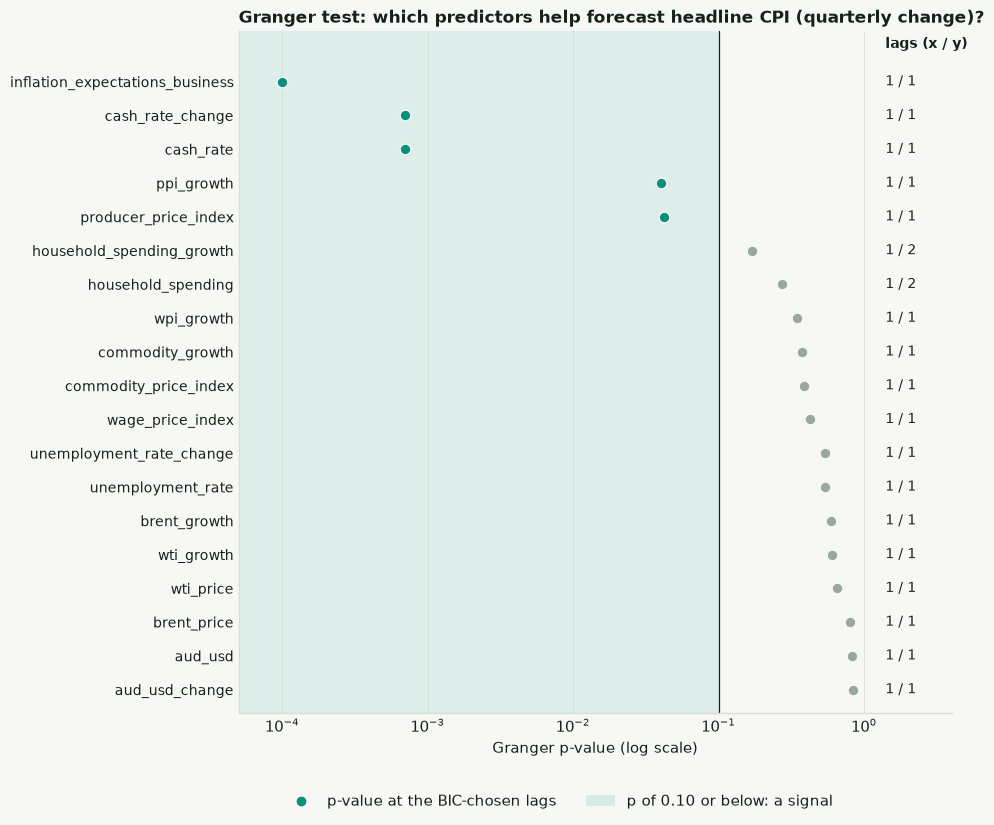

In [11]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox


def compute_granger_screens(
    target: str,
    predictor_columns: list[str],
    target_stationary_values: pd.Series,
    max_lag_limit: int = MAX_LAG,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, int]]:
    # One regression per predictor: CPI on p of its own lags plus q lags of the predictor. p and q (1 to 4)
    # are chosen by BIC on one common sample, then an F-test asks whether the q predictor lags add anything.
    def granger_screen(variable: str) -> tuple[dict[str, object], list[dict[str, object]]]:
        x = stationary_series(variable).rename(variable)
        data = pd.concat([target_stationary_values.rename('y'), x.rename('x')], axis=1).dropna()
        record = {
            'target': target,
            'variable': variable,
            'selected_lag': np.nan,
            'own_lags': np.nan,
            'granger_p_value': np.nan,
            'resid_whiteness_p': np.nan,
            'n_obs': len(data),
            'note': 'insufficient stationary observations',
        }
        if len(data) < 24 or data['x'].nunique() < 3:
            return record, []
        max_lag = min(max_lag_limit, max(1, len(data) // 10))
        lagged = {f'y{i}': data['y'].shift(i) for i in range(1, max_lag + 1)}
        lagged.update({f'x{i}': data['x'].shift(i) for i in range(1, max_lag + 1)})
        frame = pd.concat([data['y'], pd.DataFrame(lagged)], axis=1).dropna()

        def fit(own: int, predictor: int):
            columns = [f'y{i}' for i in range(1, own + 1)] + [f'x{i}' for i in range(1, predictor + 1)]
            return sm.OLS(frame['y'], sm.add_constant(frame[columns])).fit()

        bic = {(own, predictor): fit(own, predictor).bic
               for own in range(1, max_lag + 1) for predictor in range(1, max_lag + 1)}
        own, selected = min(bic, key=bic.get)
        restricted = sm.OLS(frame['y'], sm.add_constant(frame[[f'y{i}' for i in range(1, own + 1)]])).fit()
        p_by_lag = {q: float(fit(own, q).compare_f_test(restricted)[1]) for q in range(1, max_lag + 1)}
        record.update({
            'selected_lag': selected,
            'own_lags': own,
            'granger_p_value': p_by_lag[selected],
            'resid_whiteness_p': float(acorr_ljungbox(fit(own, selected).resid, lags=[4], return_df=True)['lb_pvalue'].iloc[0]),
            'n_obs': len(frame),
            'note': 'screening signal only; not structural causality',
        })
        lag_rows = [{'target': target, 'variable': variable, 'lag_quarters': q, 'granger_p_value': p,
                     'n_obs': len(frame), 'bic_selected': q == selected} for q, p in p_by_lag.items()]
        return record, lag_rows

    results = [granger_screen(column) for column in predictor_columns]
    granger_frame = pd.DataFrame([record for record, _ in results])
    lag_results = pd.DataFrame([row for _, rows in results for row in rows])
    best_lags = {row['variable']: int(row['selected_lag']) for row, _ in results if pd.notna(row['selected_lag'])}
    return granger_frame, lag_results, best_lags


def display_granger_screens(granger_frame: pd.DataFrame, lag_results: pd.DataFrame) -> None:
    with plt.rc_context(BOOK_STYLE):
        g = granger_frame.dropna(subset=['granger_p_value']).sort_values('granger_p_value', ascending=False).reset_index(drop=True)
        floor = 1e-4
        fig, ax = plt.subplots(figsize=(9.2, 0.34 * len(g) + 2.4))
        ax.axvspan(floor / 2, 0.10, color=ACCENT_SOFT, alpha=0.45, linewidth=0)
        ax.axvline(0.10, color=INK, linewidth=0.9)
        for y, r in g.iterrows():
            signal = r['granger_p_value'] <= 0.10
            ax.scatter(max(r['granger_p_value'], floor), y, s=60, color=ACCENT if signal else MUTED, edgecolor=PAPER,
                       linewidth=1.0, zorder=4)
            ax.text(1.4, y, f"{int(r['selected_lag'])} / {int(r['own_lags'])}", va="center", fontsize=10)
        ax.set_xscale("log")
        ax.set_xlim(floor / 2, 4)
        ax.set_yticks(g.index, g["variable"], fontsize=10)
        ax.set_ylim(-0.7, len(g) + 0.5)
        ax.text(1.4, len(g) - 0.1, "lags (x / y)", va="bottom", fontsize=10, fontweight="bold")
        ax.set_xlabel("Granger p-value (log scale)")
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch
        ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=ACCENT, label="p-value at the BIC-chosen lags"),
                           Patch(facecolor=ACCENT_SOFT, alpha=0.6, label="p of 0.10 or below: a signal")],
                  frameon=False, fontsize=10.5, loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=2)
        ax.set_title(f"Granger test: which predictors help forecast {screen_label(g['target'].iloc[0])}?",
                     loc="left", fontsize=12.5, fontweight="bold")
        ax.grid(axis="x", visible=True)
        plt.show()


granger, granger_lag_results, best_lag_lookup = compute_granger_screens(
    TARGET,
    CORRELATION_BASE_COLS,
    target_stationary,
)
display_granger_screens(granger, granger_lag_results)


**Interpretation.** BIC picks a single predictor lag for every series, plus one or two lags of CPI itself, so the screen is really asking whether last quarter's value adds anything. Five of the 19 series get p of 0.10 or below. Business inflation expectations (p below 0.0001) and the cash rate (p=0.0007, the same for its change) are the clear signals, and producer prices (p=0.04) follow. Oil, household spending (p=0.17 to 0.27, on only 49 observations), wages, commodity prices, unemployment and AUD/USD show no signal (p of 0.17 or higher).

The whiteness check backs the switch to quarterly CPI. Residuals pass a Ljung-Box test at lag 4 for all 19 series here. Running the same code on the YoY series, 14 of 19 fail it and 15 of 19 come out as signals, including oil (p below 0.01 for WTI and Brent growth, against 0.59 or higher here). That earlier oil signal looks like an artefact of the overlapping windows, not evidence that oil leads inflation. A miss on quarterly CPI is still weaker evidence than a hit, because the series is noisy and several predictors start late, so "no signal" means "not detectable here" and not "no relationship". Finally, this sample includes the years used for walk-forward evaluation, so the p-values describe the data and are not a clean out-of-sample test. The walk-forward results in [§4.2](../04_modeling/42_elastic_net) are.

### What survived the screen

A candidate needed a quarterly correlation of at least 0.20 or a Granger signal, plus a usable lag-1 feature. That left five features, all at lag 1. Strong: business inflation expectations, the cash rate and the cash-rate change. Optional on a shorter sample: PPI growth (VIF just over 10) and Brent growth. Brent has only 73 quarters and no Granger signal (p=0.59); it stays on the list only because it clears the 0.20 correlation cutoff.

These are shortlists. The final Elastic Net uses three macro features (expectations, the cash-rate change and PPI), and the choice between feature sets was settled on walk-forward RMSE in [4.2](../04_modeling/42_elastic_net), not on how good these numbers look. An earlier version of this screen on the YoY series found nine headline features. Those p-values were too small, because overlapping YoY windows leave autocorrelated residuals, so we no longer rely on that screen.

In [12]:
# Guard: every figure quoted in the interpretation above.
g = granger.set_index('variable')
assert len(g) == 19 and g['granger_p_value'].notna().all() and (g['selected_lag'] == 1).all() and g['own_lags'].isin([1, 2]).all()
signals = {'inflation_expectations_business', 'cash_rate', 'cash_rate_change', 'ppi_growth', 'producer_price_index'}
assert set(g.index[g['granger_p_value'] <= 0.10]) == signals
assert g.loc['inflation_expectations_business', 'granger_p_value'] < 1e-4
for name, p, tol in [('cash_rate', 0.0007, 0.0001), ('ppi_growth', 0.04, 0.001),
                     ('household_spending', 0.27, 0.005), ('household_spending_growth', 0.17, 0.005)]:
    assert abs(g.loc[name, 'granger_p_value'] - p) <= tol, name
assert round(g.loc[~g.index.isin(signals), 'granger_p_value'].min(), 2) == 0.17
assert (g['resid_whiteness_p'] > 0.05).all()
g_yoy, _, _ = compute_granger_screens(TARGET, CORRELATION_BASE_COLS, stationary_series(TARGET))
g_yoy = g_yoy.set_index('variable')
assert len(g_yoy) == 19 and (g_yoy['resid_whiteness_p'] <= 0.05).sum() == 14 and (g_yoy['granger_p_value'] <= 0.10).sum() == 15
oil = ['wti_growth', 'wti_price', 'brent_growth']
assert g_yoy.loc[oil, 'granger_p_value'].max() < 0.01 and round(g.loc[oil, 'granger_p_value'].min(), 2) == 0.59